<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: Malignancy Detection in Cellular Biopsies</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Ingestion and Transformation (4 Marks)

Import the required core analytical libraries and load the diagnostic breast cancer dataset (load the Breast Cancer dataset from `sklearn.datasets`). Construct a primary DataFrame encompassing the predictor variables, and subsequently append the diagnostic outcome as a distinct column named `target`. Display the structural properties of this newly formed DataFrame.

**Hint:** Utilize the dataset loading utilities from your primary machine learning library. Assign the predictor matrix to the columns of your tabular structure, followed by verifying the schema to confirm data types and observation counts.

**Expected Output:** A structural summary detailing the predictor and outcome columns, confirming the schema, memory usage, and basic observation metadata.

In [1]:
# Import the libraries we need
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

# Load the dataset and put the features in a DataFrame
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)

# Add the diagnosis as a new column (0 = malignant, 1 = benign)
df["target"] = data.target

# Show the structure: columns, data types, row count, memory
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

### Question 2: Exploratory Data Analysis - Missing Values and Imbalance (7 Marks)

Perform a systematic check for null or missing values across the dataset. Following this, generate a visual representation (e.g., a bar chart) to analyze the frequency distribution of the classes within the `target` column. Finally, evaluate whether the current class distribution requires rebalancing techniques prior to modeling. Print your written answer using Python `print()` statements.

**Hint:** Aggregate the null counts across all features. Use standard plotting libraries to visualize the categorical distribution of the diagnostic outcomes. Discuss the proportionality in the context of predictive bias.

**Expected Output:** A null-value diagnostic report, a clear visualization of class frequencies, and a printed analytical justification regarding the dataset's balance and subsequent preprocessing needs.

Total missing values in dataset: 0
Columns with missing values: []


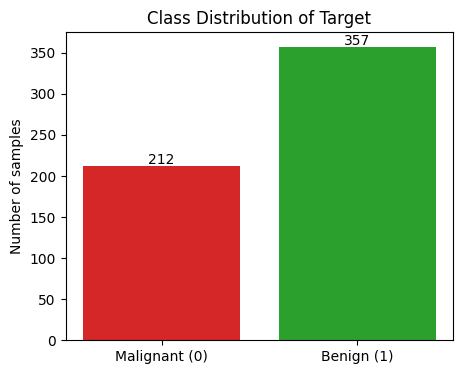

Malignant: 212 (37.3%)  |  Benign: 357 (62.7%)

Analysis:
The dataset has no missing values, so no imputation is needed.
The classes are mildly imbalanced (about 37% malignant vs 63% benign, ratio ~1:1.7).
This is not severe, so aggressive rebalancing (SMOTE, heavy under-sampling) is not required;
it could even introduce synthetic noise into a small medical dataset (569 rows).
The risk is that a model biased toward the majority (benign) class may miss malignant cases,
so we use stratified splitting and judge models by recall/F1 and ROC-AUC, not accuracy alone.


In [2]:
# Count missing values in each column
null_counts = df.isnull().sum()
print("Total missing values in dataset:", null_counts.sum())
print("Columns with missing values:", list(null_counts[null_counts > 0].index))

# Count how many samples are in each class
counts = df["target"].value_counts().sort_index()
names = ["Malignant (0)", "Benign (1)"]

# Bar chart of the class counts
plt.figure(figsize=(5, 4))
plt.bar(names, counts.values, color=["#d62728", "#2ca02c"])
for i in range(len(counts)):
    plt.text(i, counts.values[i] + 3, str(counts.values[i]), ha="center")
plt.title("Class Distribution of Target")
plt.ylabel("Number of samples")
plt.show()

pct = counts / counts.sum() * 100
print(f"Malignant: {counts[0]} ({pct[0]:.1f}%)  |  Benign: {counts[1]} ({pct[1]:.1f}%)")
print()
print("Analysis:")
print("The dataset has no missing values, so no imputation is needed.")
print(f"The classes are mildly imbalanced (about {pct[0]:.0f}% malignant vs {pct[1]:.0f}% benign, ratio ~1:{counts[1]/counts[0]:.1f}).")
print("This is not severe, so aggressive rebalancing (SMOTE, heavy under-sampling) is not required;")
print("it could even introduce synthetic noise into a small medical dataset (569 rows).")
print("The risk is that a model biased toward the majority (benign) class may miss malignant cases,")
print("so we use stratified splitting and judge models by recall/F1 and ROC-AUC, not accuracy alone.")

### Question 3: Correlation Diagnostics and Multicollinearity (8 Marks)

Construct a correlation matrix visualization (heatmap) restricted to the predictor variables. Programmatically extract and display the unique pairs of features exhibiting an absolute correlation coefficient exceeding 0.90, excluding self-correlations. Discuss the statistical risks of retaining highly correlated features in linear modeling. Print your written answer using Python `print()` statements.

**Hint:** Leverage statistical plotting functions for the heatmap. Mask the lower or upper triangle of the correlation matrix to isolate unique pairs efficiently. Consider how multicollinearity impacts coefficient stability.

**Expected Output:** A graphical heatmap of feature correlations, a programmed list of feature pairs demonstrating extreme linear dependence, and a printed analytical text explaining the potential modeling risks.

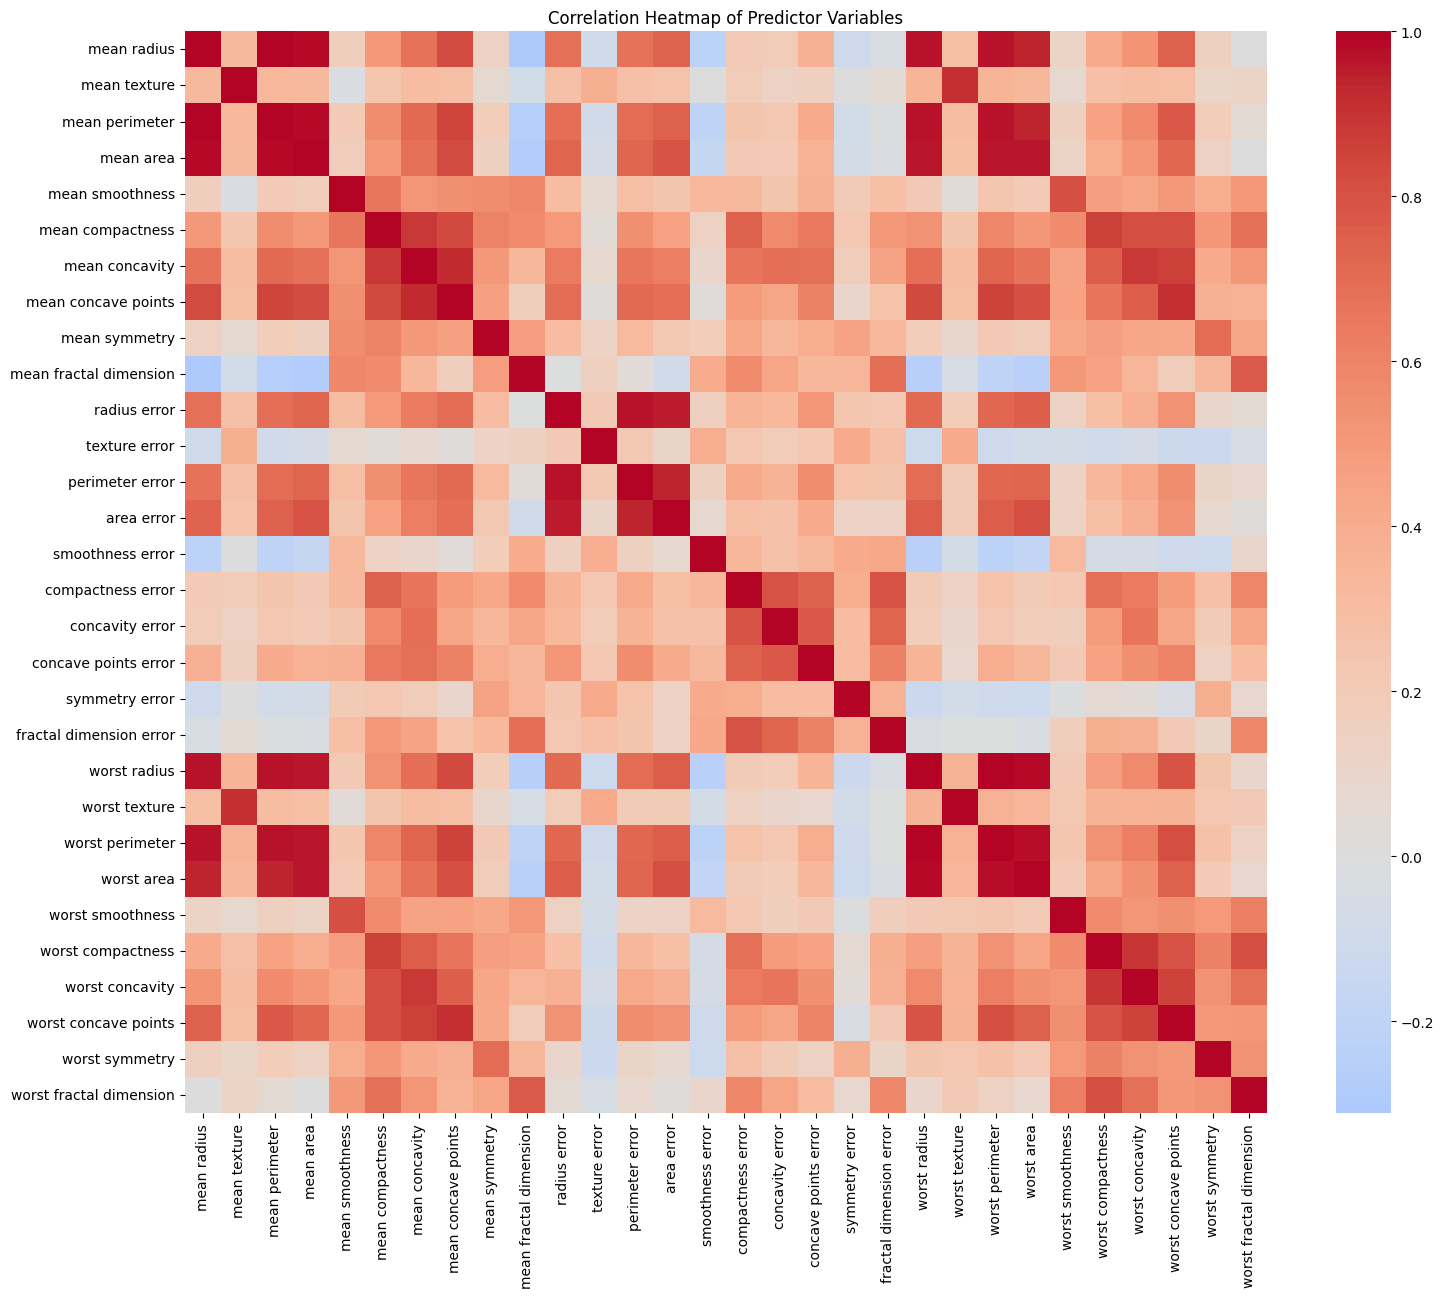

Number of unique feature pairs with |r| > 0.90: 21
          feature_1            feature_2  correlation
        mean radius       mean perimeter     0.997855
       worst radius      worst perimeter     0.993708
        mean radius            mean area     0.987357
     mean perimeter            mean area     0.986507
       worst radius           worst area     0.984015
    worst perimeter           worst area     0.977578
       radius error      perimeter error     0.972794
     mean perimeter      worst perimeter     0.970387
        mean radius         worst radius     0.969539
     mean perimeter         worst radius     0.969476
        mean radius      worst perimeter     0.965137
          mean area         worst radius     0.962746
          mean area           worst area     0.959213
          mean area      worst perimeter     0.959120
       radius error           area error     0.951830
     mean perimeter           worst area     0.941550
        mean radius           w

In [3]:
# Correlation of the features only (no target)
features = df.drop(columns="target")
corr = features.corr()

# Heatmap
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap of Predictor Variables")
plt.tight_layout()
plt.show()

# Go through the upper triangle only (j > i) so every pair is counted once
# and a feature is never compared with itself
names = list(corr.columns)
rows = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        r = corr.iloc[i, j]
        if abs(r) > 0.90:
            rows.append((names[i], names[j], r))

high_pairs = pd.DataFrame(rows, columns=["feature_1", "feature_2", "correlation"])
high_pairs = high_pairs.reindex(high_pairs["correlation"].abs().sort_values(ascending=False).index)

print(f"Number of unique feature pairs with |r| > 0.90: {len(high_pairs)}")
print(high_pairs.to_string(index=False))
print()
print("Analysis:")
print("Highly correlated predictors (multicollinearity) are risky in linear models because:")
print("1. Coefficient estimates become unstable: small changes in data cause large swings, even sign flips.")
print("2. Standard errors inflate, so individual feature effects are hard to interpret or test.")
print("3. The model cannot separate the individual contribution of correlated features (e.g. radius, perimeter, area).")
print("4. It can increase variance and overfitting, and hurts numerical conditioning of the solution.")
print("Remedies: drop redundant features, use regularisation (L1/L2), or reduce dimensions with PCA.")

### Question 4: Feature Scaling and Dimensional Retention (5 Marks)

Apply standard scaling to the numerical predictor variables to enforce a zero mean and unit variance. The `target` variable must be excluded from this transformation. To ensure analytical continuity for later interpretation, explicitly convert the scaled numerical array back into a Pandas DataFrame, ensuring the original column names are retained.

**Hint:** Initialize a standardizing transformation object and fit it strictly to the feature space. Reconstruct the tabular data structure immediately post-transformation using the extracted feature names.

**Expected Output:** A transformed tabular dataset where numerical features are standardized, column headers are perfectly preserved, and the target variable is maintained separately.

In [4]:
from sklearn.preprocessing import StandardScaler

# Keep features (X) and target (y) separate; only X gets scaled
X = df.drop(columns="target")
y = df["target"]

scaler = StandardScaler()
scaled_array = scaler.fit_transform(X)

# The scaler returns a plain array, so put the column names back
X_scaled = pd.DataFrame(scaled_array, columns=X.columns)

print("Shape:", X_scaled.shape)
print("Column names preserved:", list(X_scaled.columns) == list(X.columns))
print("Max |mean| across columns:", round(float(X_scaled.mean().abs().max()), 6))
print("Std range:", round(float(X_scaled.std(ddof=0).min()), 3), "to", round(float(X_scaled.std(ddof=0).max()), 3))
X_scaled.head()

Shape: (569, 30)
Column names preserved: True
Max |mean| across columns: 0.0
Std range: 1.0 to 1.0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100


### Question 5: Feature Engineering (6 Marks)

Based on the biomedical nature of the dataset, engineer a new composite feature. For example, compute the ratio between a "mean" feature and a "worst" feature of a specific cell measurement (e.g., area or radius). Append this engineered feature to your scaled DataFrame and verify its inclusion.

**Hint:** Select two dimensionally related features. Create a new mathematical interaction (such as a ratio or product) and assign it to a newly named column in the existing predictor dataset.

**Expected Output:** An updated predictor DataFrame that includes the newly engineered composite variable alongside the existing scaled features.

In [5]:
# New feature = mean area / worst area (how close the typical cell is to the largest one).
# I use the original unscaled values because a ratio of scaled values can be
# negative or close to zero, which makes no sense. Then I standardise the new column
# the same way as the others.
ratio = X["mean area"] / X["worst area"]
ratio_scaled = (ratio - ratio.mean()) / ratio.std(ddof=0)

X_scaled["mean_to_worst_area_ratio"] = ratio_scaled

print("Engineered feature added:", "mean_to_worst_area_ratio" in X_scaled.columns)
print("New shape:", X_scaled.shape)
X_scaled[["mean area", "worst area", "mean_to_worst_area_ratio"]].head()

Engineered feature added: True
New shape: (569, 31)


,mean area,worst area,mean_to_worst_area_ratio
0,0.984375,2.001237,-3.062857
1,1.908708,1.890489,-1.120457
2,1.558884,1.456285,-0.843094
3,-0.764464,-0.550021,-1.097009
4,1.826229,1.220724,0.432168


### Question 6: Data Partitioning and Stratification (5 Marks)

Partition the finalized feature matrix and target vector into training and testing subsets using an 80-20 ratio. Enforce stratification based on the target variable. Explain the procedural necessity of stratification in this specific context. Print your written answer using Python `print()` statements.

**Hint:** Utilize the standard partitioning utility with a fixed random seed. Review your findings from Question 2 to formulate your justification for stratified sampling.

**Expected Output:** Segregated training and testing structures with proportionate class representations, accompanied by a printed analytical justification for the chosen sampling methodology.

In [6]:
from sklearn.model_selection import train_test_split

# 80/20 split; stratify=y keeps the malignant/benign ratio the same in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, stratify=y, random_state=42
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Malignant share - full: {:.3f} | train: {:.3f} | test: {:.3f}".format(
    (y == 0).mean(), (y_train == 0).mean(), (y_test == 0).mean()))
print()
print("Why stratification:")
print("From Q2, malignant cases are the minority (~37%). A purely random split on a small dataset")
print("can by chance put too few malignant cases in the test set (or train set), giving unreliable")
print("recall estimates and a model that sees a skewed class mix. Stratification keeps the same")
print("malignant/benign ratio in both subsets, so evaluation reflects the real class balance.")

Train: (455, 31)  Test: (114, 31)
Malignant share - full: 0.373 | train: 0.374 | test: 0.368

Why stratification:
From Q2, malignant cases are the minority (~37%). A purely random split on a small dataset
can by chance put too few malignant cases in the test set (or train set), giving unreliable
recall estimates and a model that sees a skewed class mix. Stratification keeps the same
malignant/benign ratio in both subsets, so evaluation reflects the real class balance.


### Question 7: Unsupervised Outlier Detection (7 Marks)

Deploy an isolation-based anomaly detection algorithm to identify outliers strictly within the training feature subset. Filter out these anomalies from both the training features and their corresponding target labels. Document the exact number of excluded observations.

**Hint:** Initialize the anomaly detection model, fit it to the training predictors, and generate binary outlier labels. Use boolean masking to refine both the predictor matrix and the target array simultaneously.

**Expected Output:** A purified training dataset devoid of identified anomalies, along with a numerical summary of the observations purged from the system.

In [7]:
from sklearn.ensemble import IsolationForest

# Fit on the training data only. predict gives 1 for normal rows and -1 for outliers.
iso = IsolationForest(contamination=0.05, random_state=42)
labels = iso.fit_predict(X_train)
keep = labels == 1

# Remove the outliers from both the features and the labels
X_train_clean = X_train[keep]
y_train_clean = y_train[keep]

removed = (labels == -1).sum()
print("Training rows before:", len(X_train))
print("Outliers removed    :", removed)
print("Training rows after :", len(X_train_clean))
print("Malignant share after cleaning:", round((y_train_clean == 0).mean(), 3))

Training rows before: 455
Outliers removed    : 23
Training rows after : 432
Malignant share after cleaning: 0.35


### Question 8: Baseline Supervised Modeling with Cross-Validation (8 Marks)

Establish a predictive baseline using a linear probabilistic classifier (e.g., Logistic Regression). Instead of a simple single fit, evaluate the model's robustness on the cleaned training data utilizing 5-fold cross-validation. Compute and display the mean and standard deviation of the cross-validation accuracy scores.

**Hint:** Configure the baseline algorithm and employ a cross-validation utility to assess its performance across multiple folds of the training data. Aggregate the resulting metrics statistically.

**Expected Output:** A statistical summary presenting the average cross-validation accuracy and its variance, verifying the stability of the baseline algorithm.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

log_reg = LogisticRegression(max_iter=1000, random_state=42)

# 5-fold cross-validation on the cleaned training data
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(log_reg, X_train_clean, y_train_clean, cv=folds, scoring="accuracy")

print("Fold accuracies:", np.round(cv_scores, 4))
print(f"Mean CV accuracy: {cv_scores.mean():.4f}")
print(f"Std  CV accuracy: {cv_scores.std():.4f}")

Fold accuracies: [0.977  0.9885 0.9884 0.9884 0.9884]
Mean CV accuracy: 0.9861
Std  CV accuracy: 0.0046


### Question 9: Baseline Model Evaluation (5 Marks)

Train the linear baseline model on the entirety of the cleaned training dataset. Generate predictions against the unseen testing subset. Output a comprehensive classification report and a confusion matrix to evaluate terminal performance.

**Hint:** Execute the standard fitting procedure followed by inference on the test records. Pass the predicted and actual values into standard metric reporting functions.

**Expected Output:** A textual matrix detailing classification metrics (precision, recall, f1-score) and a discrete confusion matrix quantifying the distribution of true and false predictions.

               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114

Confusion matrix (rows = actual, cols = predicted):
[[41  1]
 [ 1 71]]


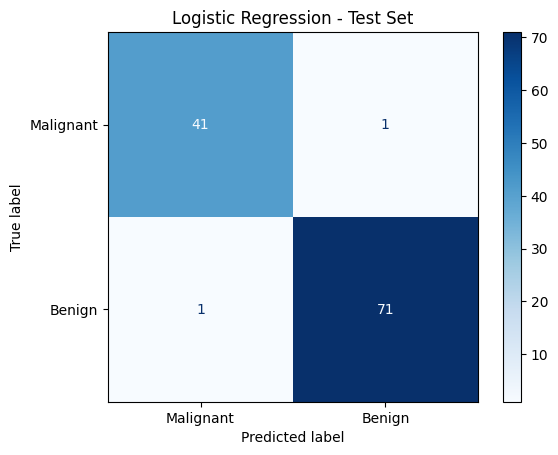

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Train on all the cleaned training data, then predict on the test data
log_reg.fit(X_train_clean, y_train_clean)
y_pred_lr = log_reg.predict(X_test)

print(classification_report(y_test, y_pred_lr, target_names=["Malignant (0)", "Benign (1)"]))

cm = confusion_matrix(y_test, y_pred_lr)
print("Confusion matrix (rows = actual, cols = predicted):")
print(cm)
ConfusionMatrixDisplay(cm, display_labels=["Malignant", "Benign"]).plot(cmap="Blues")
plt.title("Logistic Regression - Test Set")
plt.show()

### Question 10: Dimensionality Reduction (6 Marks)

Execute Principal Component Analysis (PCA) to compress the feature space of the cleaned training and testing datasets. Configure the algorithm to retain components that account for 95 percent of the cumulative variance. Discuss the trade-off between variance retention and interpretability in medical datasets. Print your written answer using Python `print()` statements.

**Hint:** Fit the reduction algorithm exclusively on the training partition before projecting both the training and testing sets into the new lower-dimensional space. Reflect on what happens to original feature names post-transformation.

**Expected Output:** Dimensionally reduced arrays for both partitions, alongside a printed analytical response evaluating the loss of direct feature interpretability versus computational efficiency.

In [10]:
from sklearn.decomposition import PCA

# n_components=0.95 means "keep enough components for 95% of the variance".
# Fit on the training data only, then apply the same transformation to the test data.
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_clean)
X_test_pca = pca.transform(X_test)

print("Original features:", X_train_clean.shape[1])
print("Components kept  :", pca.n_components_)
print("Variance retained: {:.4f}".format(pca.explained_variance_ratio_.sum()))
print("Train PCA shape:", X_train_pca.shape, "| Test PCA shape:", X_test_pca.shape)
print()
print("Trade-off analysis:")
print(f"PCA compresses {X_train_clean.shape[1]} features into {pca.n_components_} components while keeping 95% of the variance.")
print("This reduces noise, removes multicollinearity, and speeds up training/tuning.")
print("The cost is interpretability: each component is a linear mix of all original features, so we")
print("can no longer say 'this specific cell measurement drives the diagnosis'. In medicine, clinicians")
print("need to justify decisions by named measurements (radius, concavity...), so a model on PCA")
print("components is harder to explain and audit, and the 5% discarded variance might hold subtle signal.")

Original features: 31
Components kept  : 10
Variance retained: 0.9549
Train PCA shape: (432, 10) | Test PCA shape: (114, 10)

Trade-off analysis:
PCA compresses 31 features into 10 components while keeping 95% of the variance.
This reduces noise, removes multicollinearity, and speeds up training/tuning.
The cost is interpretability: each component is a linear mix of all original features, so we
can no longer say 'this specific cell measurement drives the diagnosis'. In medicine, clinicians
need to justify decisions by named measurements (radius, concavity...), so a model on PCA
components is harder to explain and audit, and the 5% discarded variance might hold subtle signal.


### Question 11: Advanced Architecture Initialization (4 Marks)

Instantiate a Multi-Layer Perceptron (MLP) algorithm. Define a preliminary architecture consisting of two hidden layers (e.g., 32 nodes followed by 16 nodes), utilizing a rectified linear activation unit, and establishing a maximum iteration limit of 500. Do not execute training in this phase.

**Hint:** Configure the network object with the specified topological and operational parameters. Maintain reproducibility through fixed random seeds.

**Expected Output:** A dormant but fully configured MLP computational object prepared for subsequent tuning and training.

In [11]:
from sklearn.neural_network import MLPClassifier

# Only creating the model here, not training it yet
mlp = MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", max_iter=500, random_state=42)
print(mlp)

MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42)


### Question 12: Hyperparameter Tuning and Optimization (12 Marks)

Construct a grid search mechanism over the initialized MLP to identify the optimal configuration. Evaluate at least two distinct hidden layer topographies and two learning rate initialization strategies. Execute the tuning process over the PCA-transformed training data using 3-fold cross-validation. Extract and print the parameters that yield the highest validation score.

**Hint:** Define a parameter dictionary targeting structural and optimization arguments. Pass the dictionary and the MLP object into an exhaustive search utility to isolate the superior architecture.

**Expected Output:** The execution of a comprehensive search algorithm resulting in the display of the mathematically optimal hyperparameter combination.

In [12]:
from sklearn.model_selection import GridSearchCV

# The options to try: 3 layer layouts x 2 learning rates = 6 combinations
param_grid = {
    "hidden_layer_sizes": [(32, 16), (64, 32), (16,)],
    "learning_rate_init": [0.001, 0.01],
}

grid = GridSearchCV(mlp, param_grid, cv=3, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_pca, y_train_clean)

print("Best parameters :", grid.best_params_)
print("Best CV accuracy: {:.4f}".format(grid.best_score_))
best_mlp = grid.best_estimator_

Best parameters : {'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.001}
Best CV accuracy: 0.9838


### Question 13: ROC Curve Analysis (6 Marks)

Utilize both the baseline linear model and the optimized MLP model to compute prediction probabilities for the positive diagnostic class on the testing set. Calculate the Area Under the Receiver Operating Characteristic Curve (ROC-AUC) for both models. Compare their discriminatory capabilities. Print your written answer using Python `print()` statements.

**Hint:** Extract the continuous probability estimates rather than discrete labels. Map these against the true test labels to derive the area metric for each algorithmic approach.

**Expected Output:** Quantitative AUC scores for both algorithms and a printed analytical synthesis comparing their relative effectiveness at distinguishing between classes.

ROC-AUC  Logistic Regression: 0.9974
ROC-AUC  Optimised MLP      : 0.9957


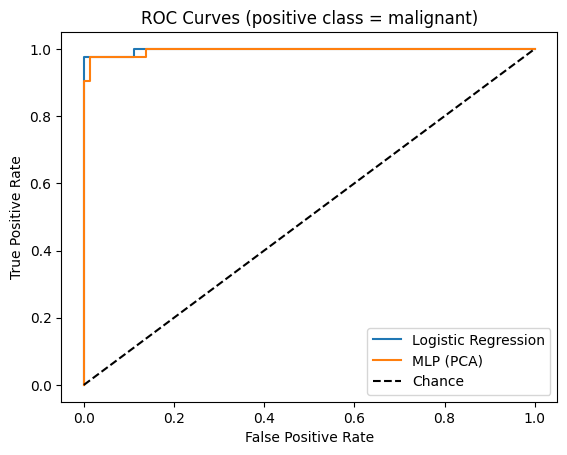


Comparison:
Both models separate malignant from benign cases extremely well (AUC close to 1.0).
Logistic Regression has the slightly higher AUC (difference = 0.0017), but the gap is tiny
on a test set of only 114 samples, so it is within noise. The simple linear model is already
near-optimal here because the classes are almost linearly separable, which means the added
complexity of the MLP (and its loss of interpretability via PCA) brings little benefit.


In [13]:
from sklearn.metrics import roc_auc_score, roc_curve

# Malignant (label 0) is the positive class here, so I turn the labels around
# and use column 0 of predict_proba (the probability of malignant)
y_test_pos = (y_test == 0).astype(int)
p_lr = log_reg.predict_proba(X_test)[:, 0]
p_mlp = best_mlp.predict_proba(X_test_pca)[:, 0]

auc_lr = roc_auc_score(y_test_pos, p_lr)
auc_mlp = roc_auc_score(y_test_pos, p_mlp)
print(f"ROC-AUC  Logistic Regression: {auc_lr:.4f}")
print(f"ROC-AUC  Optimised MLP      : {auc_mlp:.4f}")

# ROC curves
fpr1, tpr1, _ = roc_curve(y_test_pos, p_lr)
fpr2, tpr2, _ = roc_curve(y_test_pos, p_mlp)
plt.plot(fpr1, tpr1, label="Logistic Regression")
plt.plot(fpr2, tpr2, label="MLP (PCA)")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (positive class = malignant)")
plt.legend()
plt.show()

better = "Logistic Regression" if auc_lr > auc_mlp else "MLP"
print()
print("Comparison:")
print(f"Both models separate malignant from benign cases extremely well (AUC close to 1.0).")
print(f"{better} has the slightly higher AUC (difference = {abs(auc_lr - auc_mlp):.4f}), but the gap is tiny")
print("on a test set of only 114 samples, so it is within noise. The simple linear model is already")
print("near-optimal here because the classes are almost linearly separable, which means the added")
print("complexity of the MLP (and its loss of interpretability via PCA) brings little benefit.")

### Question 14: Custom Diagnostic Cost Function (10 Marks)

In healthcare, missing a malignant diagnosis (a false negative) carries far greater risk than a false alarm (a false positive). Define a custom Python function to compute a weighted penalty score: assign a penalty of 10 to every false negative and a penalty of 1 to every false positive. Apply this evaluation metric to the predictions generated by your optimized MLP and output the final penalty score.

**Hint:** Your function should accept true vectors and prediction vectors. Programmatically isolate cases where truth is positive but prediction is negative, and cases where truth is negative but prediction is positive, multiplying counts by their respective penalties before summation.

**Expected Output:** A single scalar value representing the total cumulative diagnostic penalty for the advanced model, reflecting asymmetrical real-world consequences.

In [14]:
def diagnostic_penalty(y_true, y_pred):
    # Malignant = 0, benign = 1
    # False negative = really malignant but predicted benign -> penalty 10
    # False positive = really benign but predicted malignant -> penalty 1
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    false_neg = np.sum((y_true == 0) & (y_pred == 1))
    false_pos = np.sum((y_true == 1) & (y_pred == 0))
    return 10 * false_neg + 1 * false_pos

y_pred_mlp = best_mlp.predict(X_test_pca)

fn = np.sum((y_test.values == 0) & (y_pred_mlp == 1))
fp = np.sum((y_test.values == 1) & (y_pred_mlp == 0))
print(f"False negatives: {fn} | False positives: {fp}")
print("Total diagnostic penalty (optimised MLP):", diagnostic_penalty(y_test, y_pred_mlp))
print("For reference, baseline logistic regression penalty:", diagnostic_penalty(y_test, y_pred_lr))

False negatives: 1 | False positives: 2
Total diagnostic penalty (optimised MLP): 12
For reference, baseline logistic regression penalty: 11


### Question 15: Feature Importance and Analytical Conclusion (7 Marks)

Revisit your trained baseline linear model from Question 9. Extract its learned coefficients and correlate them with the original feature names preserved during Question 4. Identify and output the three features exerting the strongest absolute magnitude on the prediction. Summarize the diagnostic implications of these top predictors. Print your written answer using Python `print()` statements.

**Hint:** Align the model's coefficient array with the column index of your standardized DataFrame. Sort the aggregated pairs by absolute value to isolate the dominant variables.

**Expected Output:** A structured display of the top three critical biomedical features along with their respective coefficient weights, concluded by a printed analytical narrative summarizing their clinical relevance.

In [15]:
# Match each coefficient with its feature name
coef = pd.Series(log_reg.coef_[0], index=X_train_clean.columns)

# Sort by size ignoring the sign, and keep the top 3
order = coef.abs().sort_values(ascending=False).index
top3 = coef[order].head(3)

print("Top 3 features by absolute coefficient:")
print(top3.round(4).to_string())
print()
print("Analysis:")
print("The model predicts class 1 = benign, so a NEGATIVE coefficient means a higher (standardised)")
print("value of that feature pushes the prediction toward MALIGNANT, and a positive one toward benign.")
for name, c in top3.items():
    direction = "malignancy" if c < 0 else "benign diagnosis"
    print(f" - {name}: coefficient {c:+.3f} -> larger values favour {direction}.")
print("The engineered mean-to-worst area ratio carries the largest weight: a high ratio means the typical")
print("nucleus is close in size to the largest nucleus in the sample (uniform cells), which points to benign.")
print("Higher 'worst texture' (greater variation in grey-level intensity) and higher 'mean concave points'")
print("(more indentations in the cell contour) push the prediction toward malignant, consistent with clinical")
print("knowledge that malignant nuclei are irregular in shape and texture. These are the measurements a")
print("pathologist would most want to review, although coefficients of correlated features should be")
print("read with caution (see Q3).")

Top 3 features by absolute coefficient:
mean_to_worst_area_ratio    1.3594
worst texture              -0.9751
mean concave points        -0.9412

Analysis:
The model predicts class 1 = benign, so a NEGATIVE coefficient means a higher (standardised)
value of that feature pushes the prediction toward MALIGNANT, and a positive one toward benign.
 - mean_to_worst_area_ratio: coefficient +1.359 -> larger values favour benign diagnosis.
 - worst texture: coefficient -0.975 -> larger values favour malignancy.
 - mean concave points: coefficient -0.941 -> larger values favour malignancy.
The engineered mean-to-worst area ratio carries the largest weight: a high ratio means the typical
nucleus is close in size to the largest nucleus in the sample (uniform cells), which points to benign.
Higher 'worst texture' (greater variation in grey-level intensity) and higher 'mean concave points'
(more indentations in the cell contour) push the prediction toward malignant, consistent with clinical
knowledg